[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kabir7code/pathsnap/blob/main/notebooks/04_Decision_Tree_Random_Forest_Extra_Trees.ipynb)

# 04. Tree-based and bagging ensembles: Decision Tree, Random Forest, Extra Trees
**Run on:** Laptop A · **Approx. runtime:** ~8-12 min on a 4-core laptop


**Protocol (same for every model):**
- Each row is one *(GPS point, candidate arc)* pair. The label is 1 if the arc is the point's reference arc.
- **5-fold GroupKFold by trip** on the 78 usable training trips. Each fold fits on a 300k-row sample of points (KNN uses 100k) and is scored on all candidates of the held-out trips.
- The model is then **refit on the training split** and scored on the **10 student-test trips**.
- **Metrics:**
  - macro F1 / precision / recall: candidate level, threshold 0.5
  - log loss
  - **Top-1 accuracy**: the share of GPS points whose highest-scoring candidate is the reference arc
  - continuity
- The **HMM/Viterbi** decoder (parameters in `models/hmm_params.json`) is then run on this model's probabilities to compare *classifier only* with *classifier + HMM*.


**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

**On Google Colab:** run the next cell first. It clones the repo, installs packages and loads `Student_folder.zip` from your Google Drive (`MyDrive/Student_folder.zip`) or asks you to upload it. Locally it does nothing.

In [ ]:
# ── Google Colab setup ── (skipped automatically when running locally)
import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    REPO = "/content/pathsnap"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/Kabir7code/pathsnap.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "lightgbm", "folium", "pyarrow"], check=True)
    if not (os.path.isdir("data/train") and os.path.isdir("data/student_test")):
        # 1) put Student_folder.zip in your Google Drive (MyDrive) -- or 2) upload it when asked
        DATA_ZIP = "/content/drive/MyDrive/Student_folder.zip"
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
        if not os.path.exists(DATA_ZIP):
            from google.colab import files
            print("Student_folder.zip not found in Drive. Please upload it:")
            DATA_ZIP = "/content/" + list(files.upload())[0]
        raw = "/content/_raw"
        shutil.rmtree(raw, ignore_errors=True)
        zipfile.ZipFile(DATA_ZIP).extractall(raw)
        src = next(d for d, sub, _ in os.walk(raw) if "train" in sub and "student_test" in sub)
        os.makedirs("data", exist_ok=True)
        for part in ("train", "student_test"):
            shutil.move(os.path.join(src, part), os.path.join("data", part))
    print("Colab ready:", os.getcwd(), "| train trips:", len(os.listdir("data/train")),
          "| student_test trips:", len(os.listdir("data/student_test")))

In [1]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap


In [2]:
tr, tr_pts, te, te_pts = nb.load_data()

feature tables found in artifacts/


train: 78 trips, 1,028,261 candidate rows, positive rate 0.175
student_test: 10 trips, 113,636 candidate rows


## Decision Tree


**What it does:** a flowchart of yes/no splits on features (e.g. *dist_minus_min ≤ 0?*, *heading_diff ≤ 40°?*) ending in leaves with a probability.
- **Why it suits PathSnap:** captures feature interactions and thresholds naturally; no scaling needed.
- **Limitation:** one tree is high-variance, so it is regularised here.
- **Hyperparameters:** max_depth = 12, min_samples_leaf = 50.
- **Objective:** Gini impurity reduction at each split.

In [3]:
make_dtree = lambda: make_model("dtree", SEED)
print(make_dtree())
cv_dtree = nb.run_cv(make_dtree, tr, tr_pts, max_rows=300000)
cv_dtree.round(4)

DecisionTreeClassifier(max_depth=12, min_samples_leaf=50, random_state=42)


  fold 0: F1=0.9130 top1=0.8589 ll=0.1660


  fold 1: F1=0.9303 top1=0.8837 ll=0.1151


  fold 2: F1=0.9156 top1=0.8690 ll=0.1847


  fold 3: F1=0.9477 top1=0.9210 ll=0.0921


  fold 4: F1=0.9086 top1=0.8522 ll=0.1526


CV time 15s | mean macro F1 0.9230 ± 0.0160


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.9130,0.8763,0.8388,0.1660,0.8589,0.0166,0.0004,2.4133
1,0.9303,0.8985,0.8642,0.1151,0.8837,0.0263,0.0008,2.7231
2,0.9156,0.8678,0.8650,0.1847,0.8690,0.0228,0.0005,2.5265
3,0.9477,0.9219,0.9040,0.0921,0.9210,0.0189,0.0005,2.3923
4,0.9086,0.8729,0.8210,0.1526,0.8522,0.0199,0.0006,2.3294


In [4]:
model_dtree, train_dtree, test_dtree, p_dtree = nb.fit_and_evaluate(make_dtree, tr, tr_pts, te, te_pts, max_rows=300000)
print(f"student-test continuity (classifier only): {test_dtree['continuity']:.4f} | inference {test_dtree['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("Decision Tree", cv_dtree, train_dtree, test_dtree)

fit 2.6s on 300,108 rows
student-test continuity (classifier only): 0.9231 | inference 0.0005 ms/point


Decision Tree,train (fit sample),CV mean (5 folds),student test
macro F1,0.9328,0.9230,0.9224
precision,0.8947,0.8875,0.8753
recall,0.8831,0.8586,0.8662
log loss,0.1000,0.1421,0.1293
Top-1 accuracy,0.8943,0.8770,0.8756


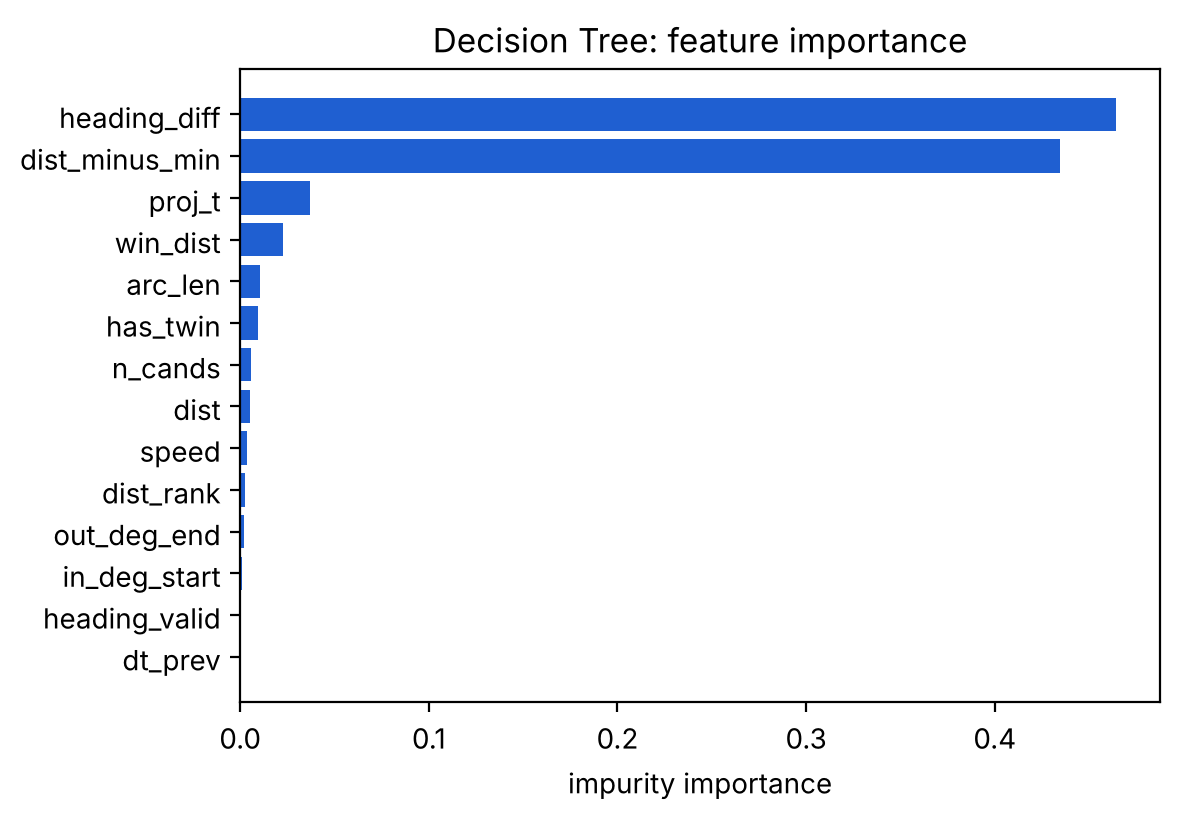

In [5]:
imp_dtree = nb.plot_importance(model_dtree, te, "Decision Tree")

Decision Tree: mean over 10 trips
cls_top1          0.8912
hmm_top1          0.9439
cls_route_f1      0.7660
hmm_route_f1      0.9539
cls_continuity    0.9231
hmm_continuity    0.9767


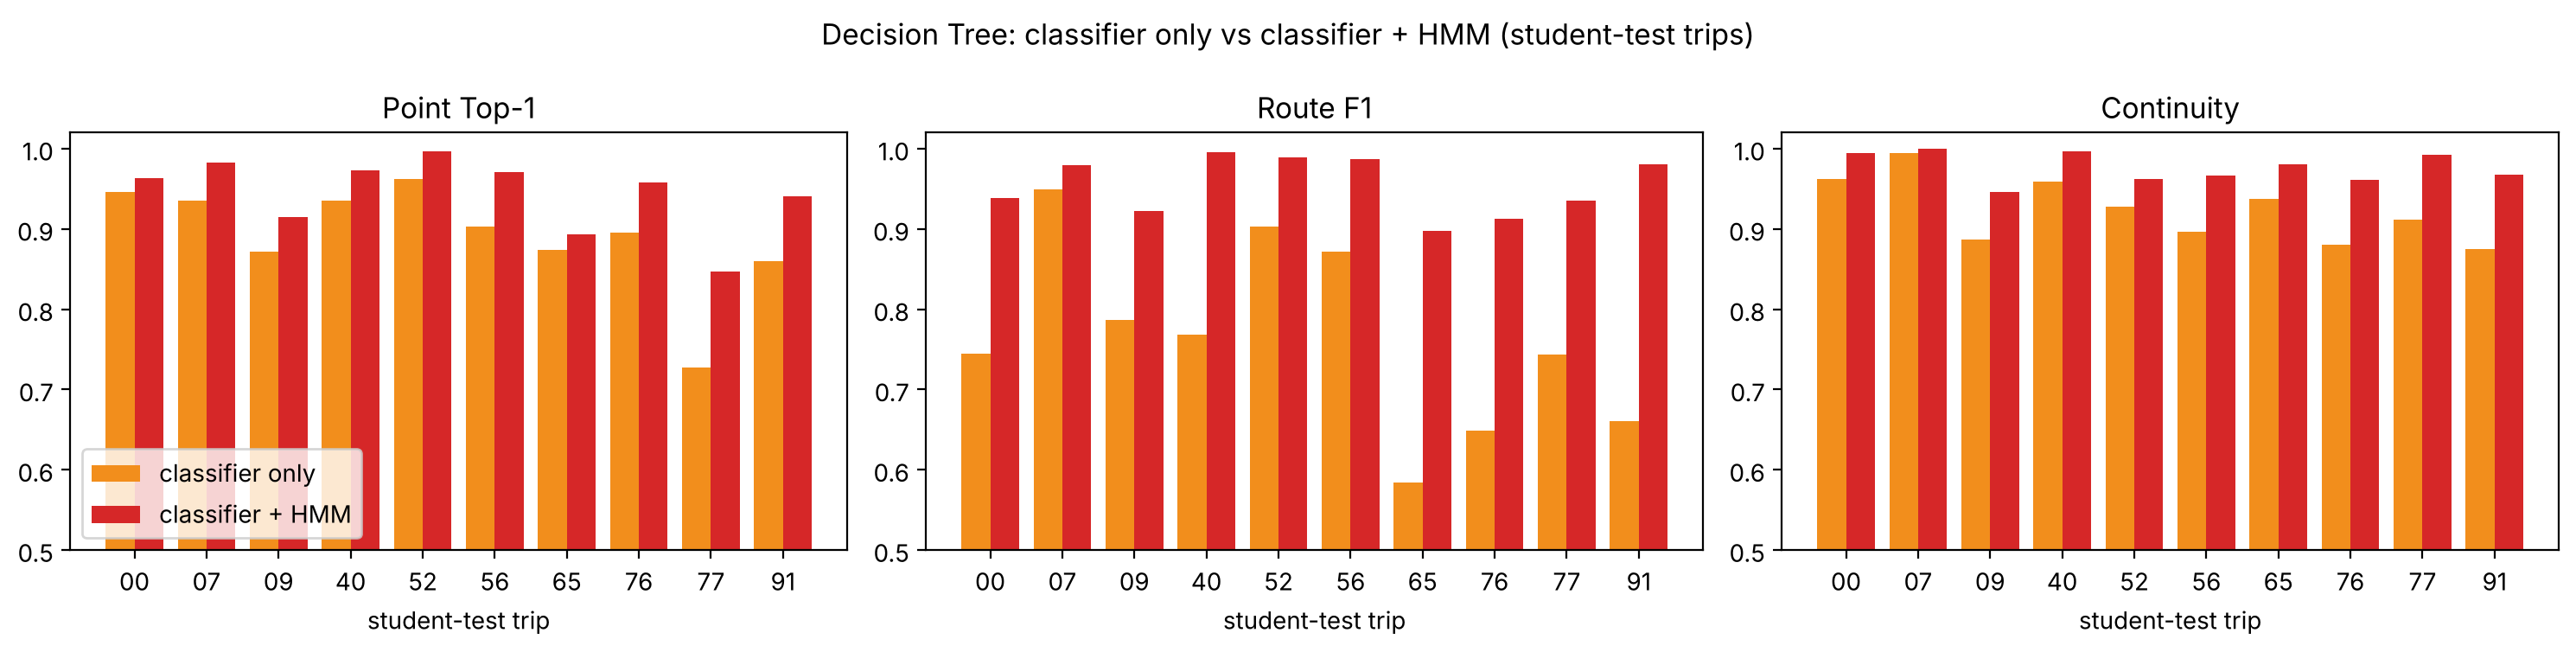

saved results/notebooks/dtree.json


In [6]:
hmm_dtree = nb.hmm_compare(model_dtree, te, "Decision Tree")
nb.plot_hmm(hmm_dtree, "Decision Tree: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("dtree", cv_dtree, train_dtree, test_dtree,
                {"hmm_mean": hmm_dtree.drop(columns=["trip", "model"]).mean().to_dict()})

## Random Forest


**What it does:** 200 decision trees, each trained on a bootstrap sample with random feature subsets (sqrt of 14) at each split; probabilities are averaged.
- **Why:** averaging de-correlated trees reduces the variance of a single tree.
- **Limitation:** large model files (about 18 MB) and slower than boosting at similar accuracy.
- **Hyperparameters:** n_estimators = 200, max_depth = 16, min_samples_leaf = 20.
- **Objective:** Gini impurity per tree.

In [7]:
make_rf = lambda: make_model("rf", SEED)
print(make_rf())
cv_rf = nb.run_cv(make_rf, tr, tr_pts, max_rows=300000)
cv_rf.round(4)

RandomForestClassifier(max_depth=16, min_samples_leaf=20, n_estimators=200,
                       n_jobs=-1, random_state=42)


  fold 0: F1=0.9151 top1=0.8618 ll=0.1359


  fold 1: F1=0.9317 top1=0.8842 ll=0.0976


  fold 2: F1=0.9192 top1=0.8739 ll=0.1380


  fold 3: F1=0.9493 top1=0.9240 ll=0.0822


  fold 4: F1=0.9077 top1=0.8546 ll=0.1253


CV time 212s | mean macro F1 0.9246 ± 0.0163


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.9151,0.8940,0.8288,0.1359,0.8618,1.0710,0.0282,42.0078
1,0.9317,0.9218,0.8473,0.0976,0.8842,1.0576,0.0340,40.5372
2,0.9192,0.8919,0.8517,0.1380,0.8739,0.9054,0.0209,42.7055
3,0.9493,0.9414,0.8904,0.0822,0.9240,1.3177,0.0382,40.0704
4,0.9077,0.8955,0.7981,0.1253,0.8546,1.4732,0.0434,39.0305


In [8]:
model_rf, train_rf, test_rf, p_rf = nb.fit_and_evaluate(make_rf, tr, tr_pts, te, te_pts, max_rows=300000)
print(f"student-test continuity (classifier only): {test_rf['continuity']:.4f} | inference {test_rf['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("Random Forest", cv_rf, train_rf, test_rf)

fit 39.5s on 300,108 rows
student-test continuity (classifier only): 0.9253 | inference 0.0325 ms/point


Random Forest,train (fit sample),CV mean (5 folds),student test
macro F1,0.9351,0.9246,0.9224
precision,0.9206,0.9089,0.9002
recall,0.8655,0.8433,0.8417
log loss,0.0959,0.1158,0.1105
Top-1 accuracy,0.8979,0.8797,0.8777


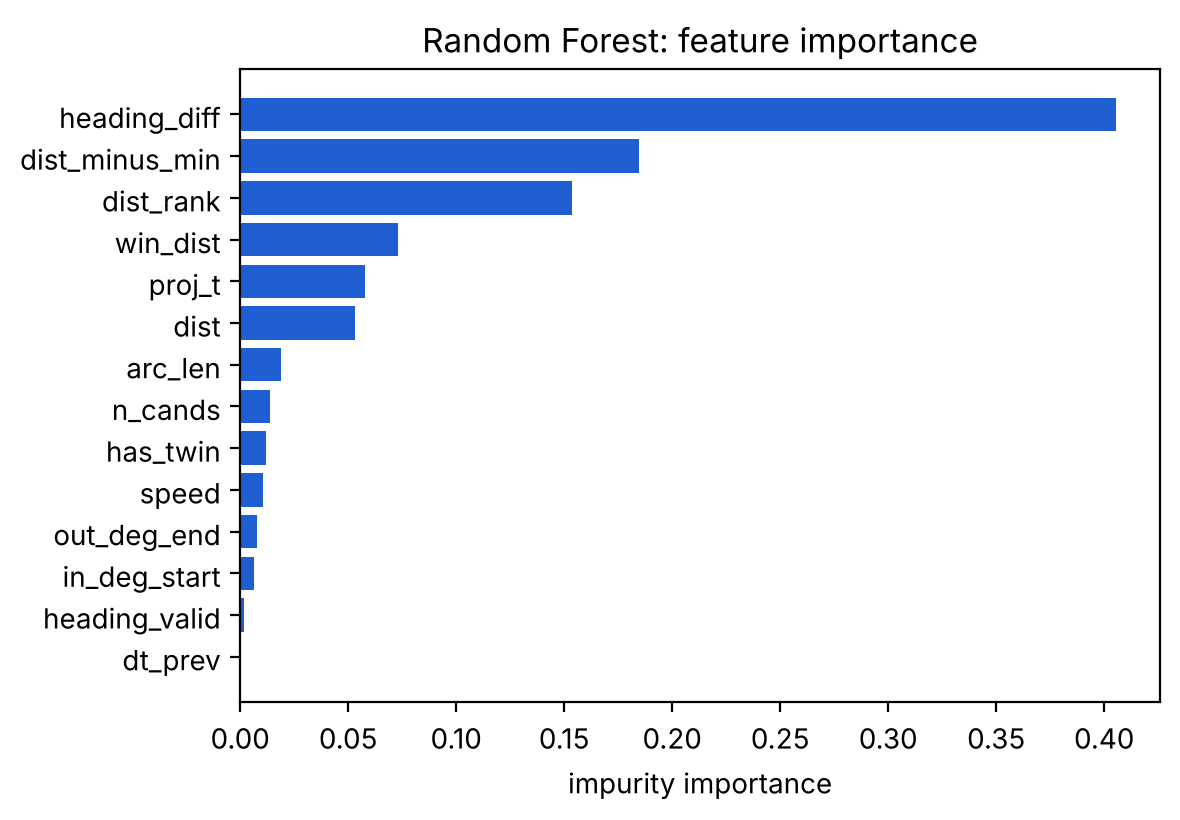

In [9]:
imp_rf = nb.plot_importance(model_rf, te, "Random Forest")

Random Forest: mean over 10 trips
cls_top1          0.8937
hmm_top1          0.9493
cls_route_f1      0.7650
hmm_route_f1      0.9577
cls_continuity    0.9253
hmm_continuity    0.9775


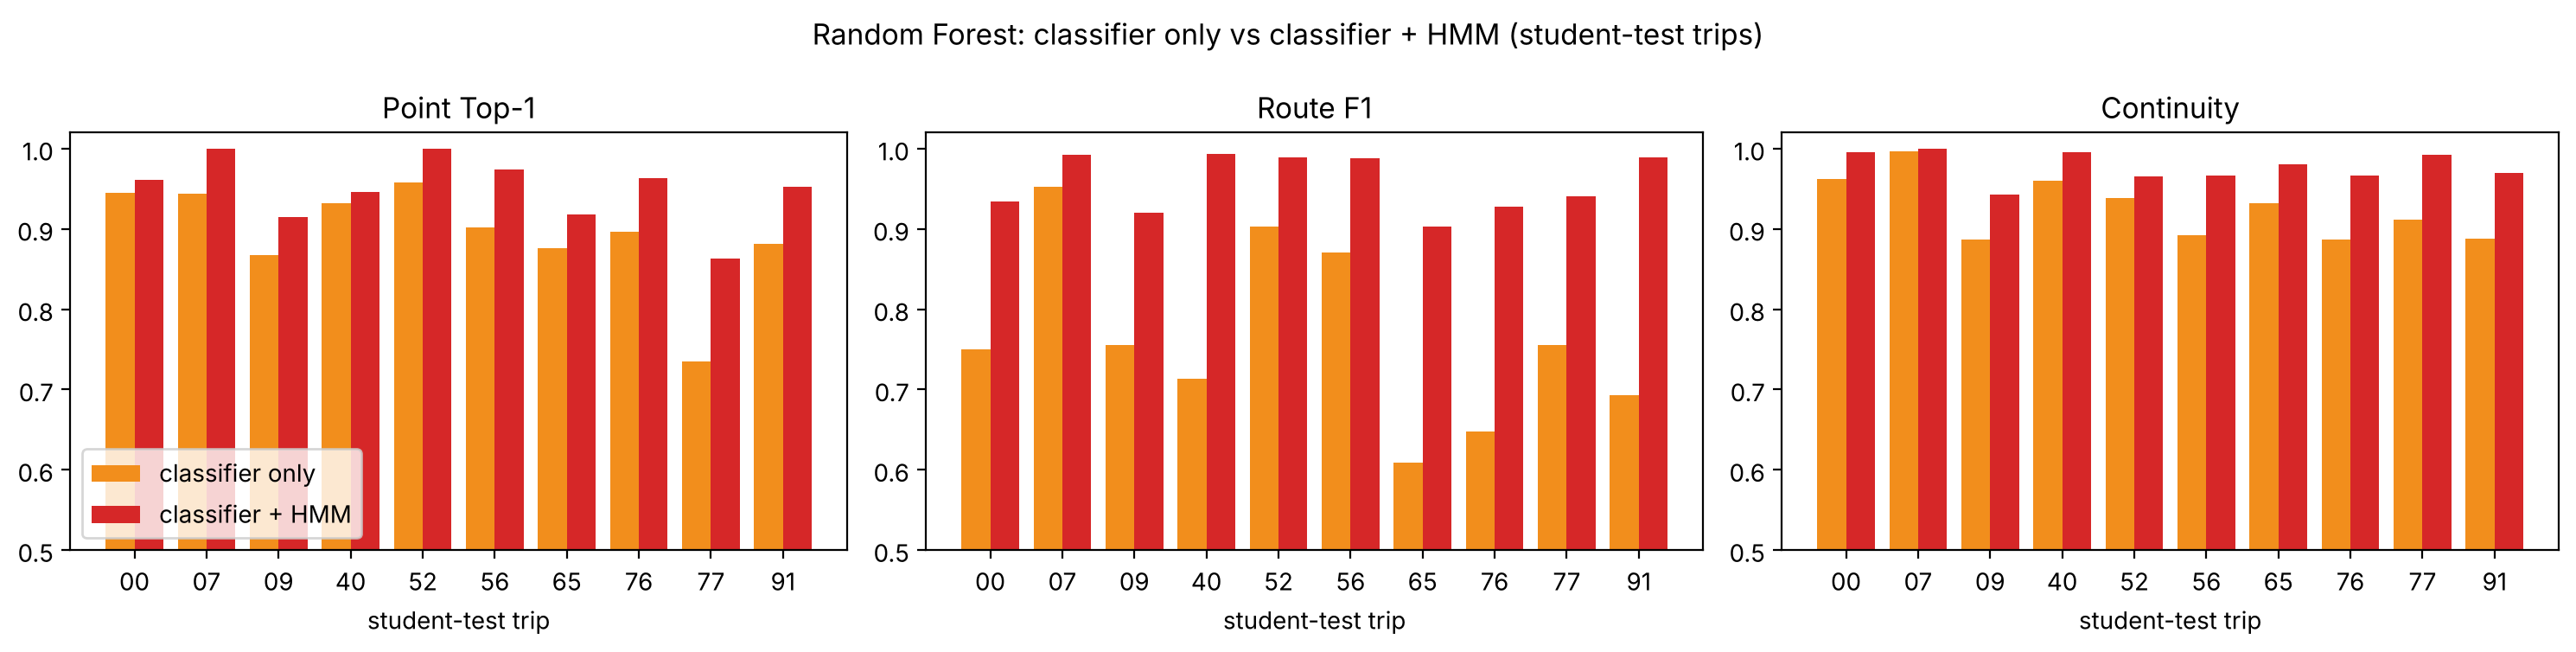

saved results/notebooks/rf.json


In [10]:
hmm_rf = nb.hmm_compare(model_rf, te, "Random Forest")
nb.plot_hmm(hmm_rf, "Random Forest: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("rf", cv_rf, train_rf, test_rf,
                {"hmm_mean": hmm_rf.drop(columns=["trip", "model"]).mean().to_dict()})

## Extra Trees


**What it does:** like Random Forest, but split thresholds are drawn **at random** and the best random split is kept, which adds even more randomisation.
- **Why tried:** often as accurate as RF and faster to train.
- **Limitation:** random thresholds are less precise on the key distance and heading features; here it is the weakest tree ensemble.
- **Hyperparameters:** n_estimators = 200, max_depth = 18, min_samples_leaf = 20.
- **Objective:** Gini impurity.

In [11]:
make_extratrees = lambda: make_model("extratrees", SEED)
print(make_extratrees())
cv_extratrees = nb.run_cv(make_extratrees, tr, tr_pts, max_rows=300000)
cv_extratrees.round(4)

ExtraTreesClassifier(max_depth=18, min_samples_leaf=20, n_estimators=200,
                     n_jobs=-1, random_state=42)


  fold 0: F1=0.9111 top1=0.8554 ll=0.1525


  fold 1: F1=0.9267 top1=0.8677 ll=0.1243


  fold 2: F1=0.9073 top1=0.8611 ll=0.1653


  fold 3: F1=0.9426 top1=0.9071 ll=0.1115


  fold 4: F1=0.9002 top1=0.8374 ll=0.1450


CV time 56s | mean macro F1 0.9176 ± 0.0170


,macro_f1,precision,recall,log_loss,top1,infer_s,infer_ms_per_point,fit_s
fold,,,,,,,,
0,0.9111,0.8981,0.8126,0.1525,0.8554,1.1081,0.0292,10.3394
1,0.9267,0.9163,0.8362,0.1243,0.8677,1.0974,0.0353,9.0387
2,0.9073,0.8973,0.8102,0.1653,0.8611,0.8444,0.0195,10.2375
3,0.9426,0.9421,0.8685,0.1115,0.9071,1.0334,0.0300,9.2565
4,0.9002,0.8927,0.7773,0.1450,0.8374,1.3474,0.0396,9.7240


In [12]:
model_extratrees, train_extratrees, test_extratrees, p_extratrees = nb.fit_and_evaluate(make_extratrees, tr, tr_pts, te, te_pts, max_rows=300000)
print(f"student-test continuity (classifier only): {test_extratrees['continuity']:.4f} | inference {test_extratrees['infer_ms_per_point']:.4f} ms/point")
nb.summary_table("Extra Trees", cv_extratrees, train_extratrees, test_extratrees)

fit 10.7s on 300,108 rows
student-test continuity (classifier only): 0.9060 | inference 0.0341 ms/point


Extra Trees,train (fit sample),CV mean (5 folds),student test
macro F1,0.9198,0.9176,0.9158
precision,0.9124,0.9093,0.9022
recall,0.8248,0.8209,0.8190
log loss,0.1377,0.1397,0.1400
Top-1 accuracy,0.8710,0.8657,0.8552


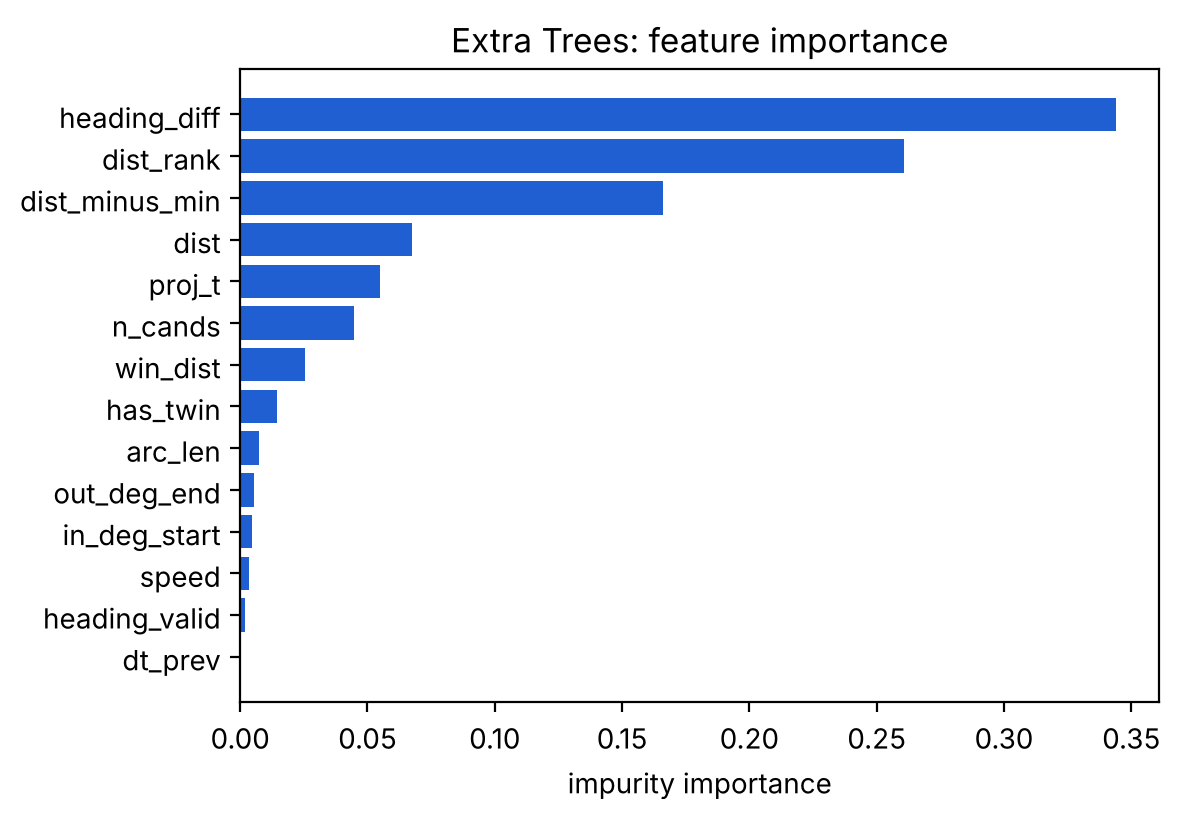

In [13]:
imp_extratrees = nb.plot_importance(model_extratrees, te, "Extra Trees")

Extra Trees: mean over 10 trips
cls_top1          0.8684
hmm_top1          0.9478
cls_route_f1      0.7022
hmm_route_f1      0.9586
cls_continuity    0.9060
hmm_continuity    0.9777


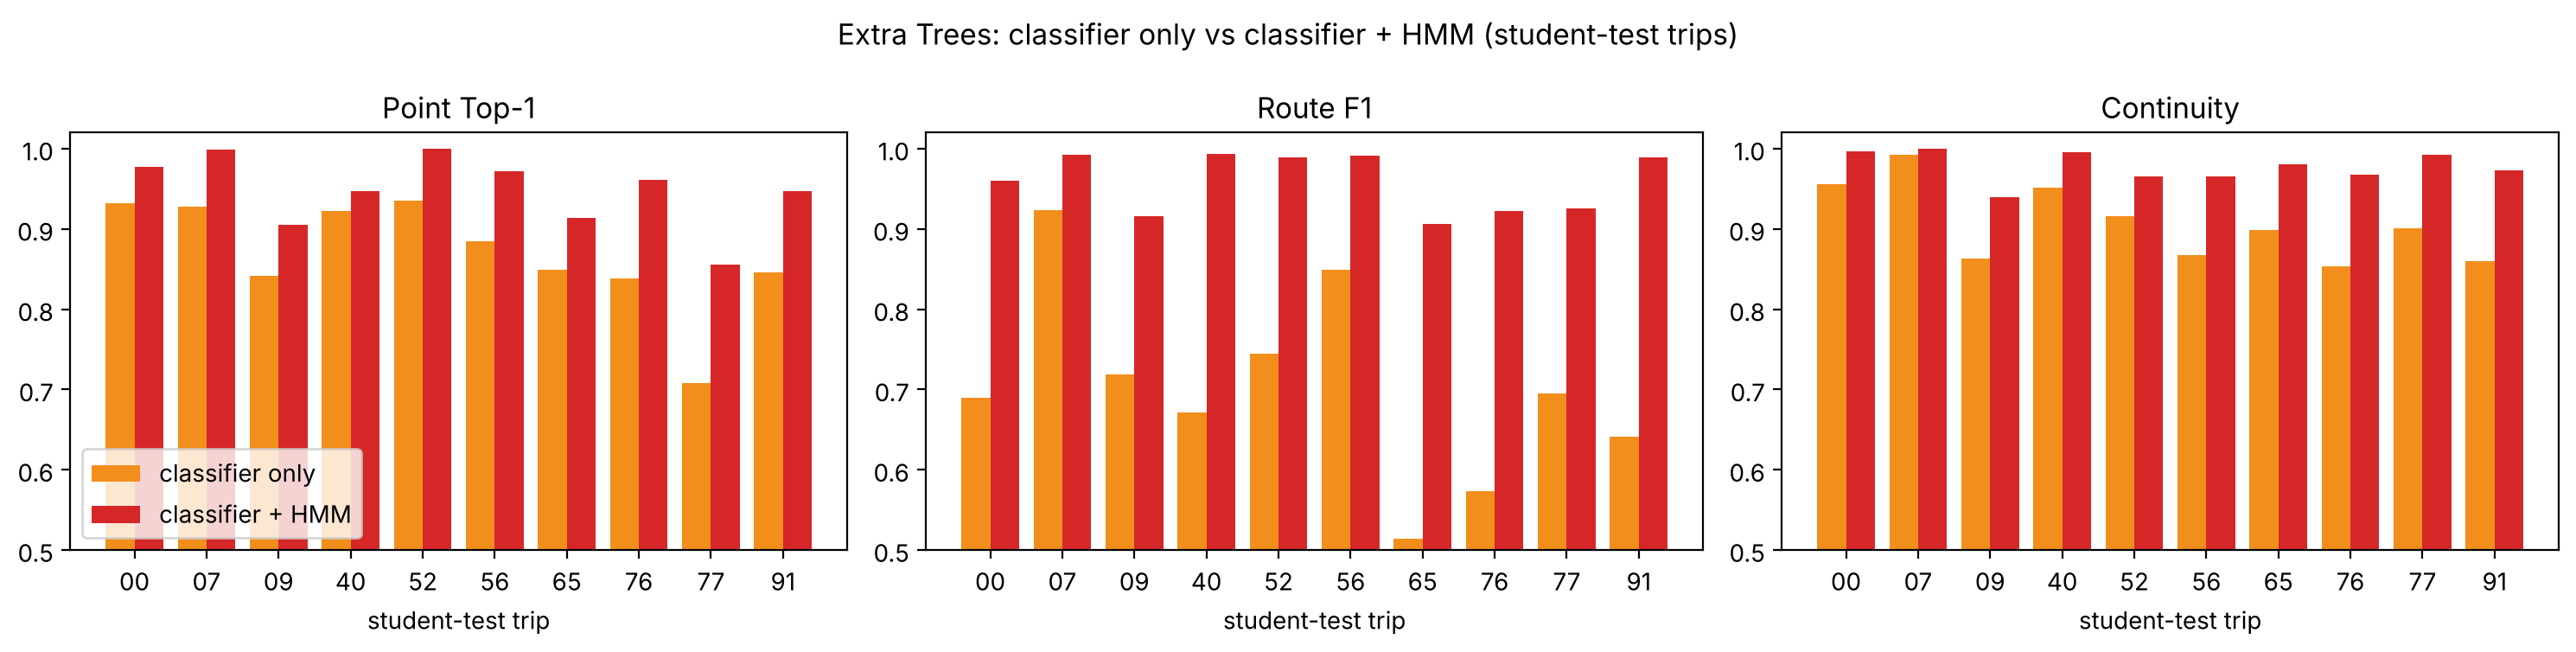

saved results/notebooks/extratrees.json


In [14]:
hmm_extratrees = nb.hmm_compare(model_extratrees, te, "Extra Trees")
nb.plot_hmm(hmm_extratrees, "Extra Trees: classifier only vs classifier + HMM (student-test trips)")
nb.save_results("extratrees", cv_extratrees, train_extratrees, test_extratrees,
                {"hmm_mean": hmm_extratrees.drop(columns=["trip", "model"]).mean().to_dict()})

## Comparison of the models in this notebook

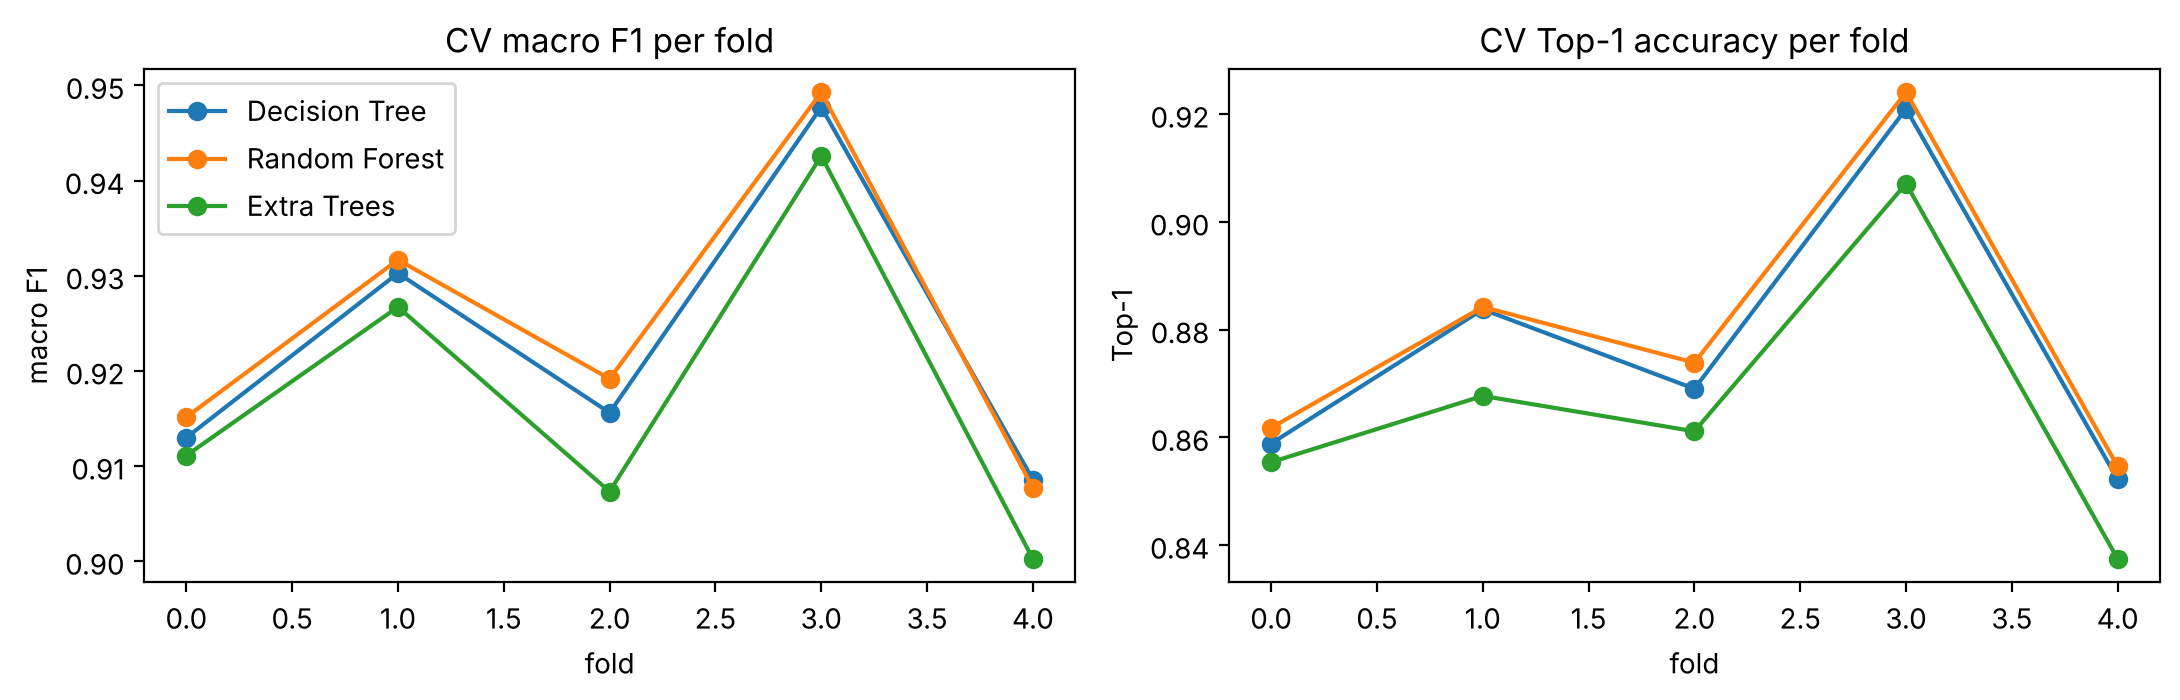

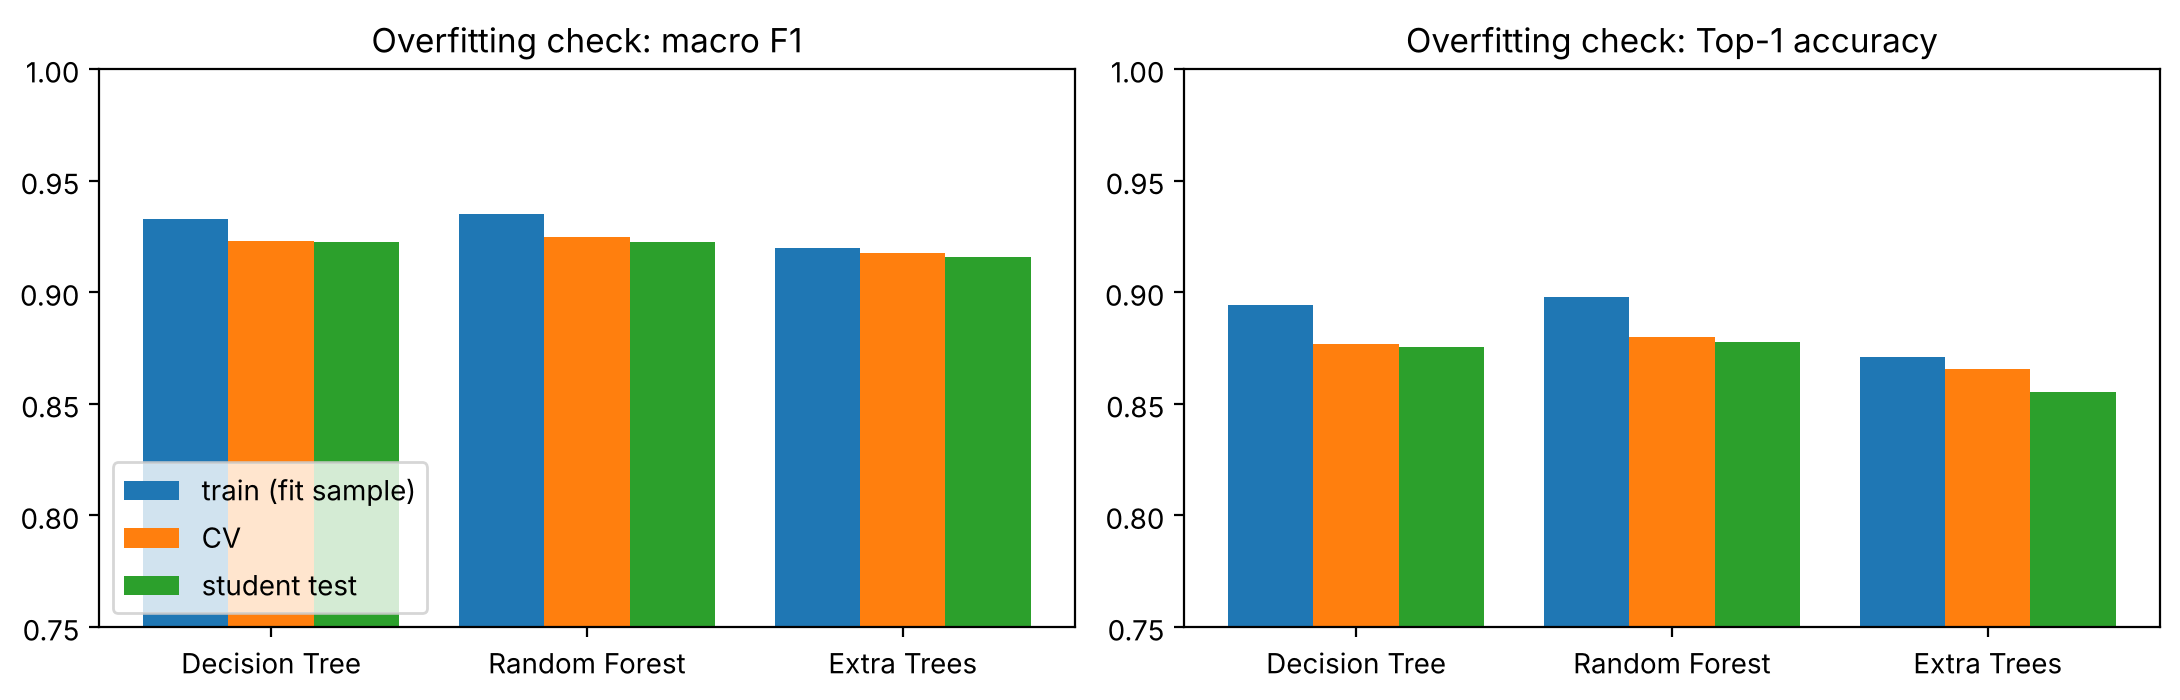

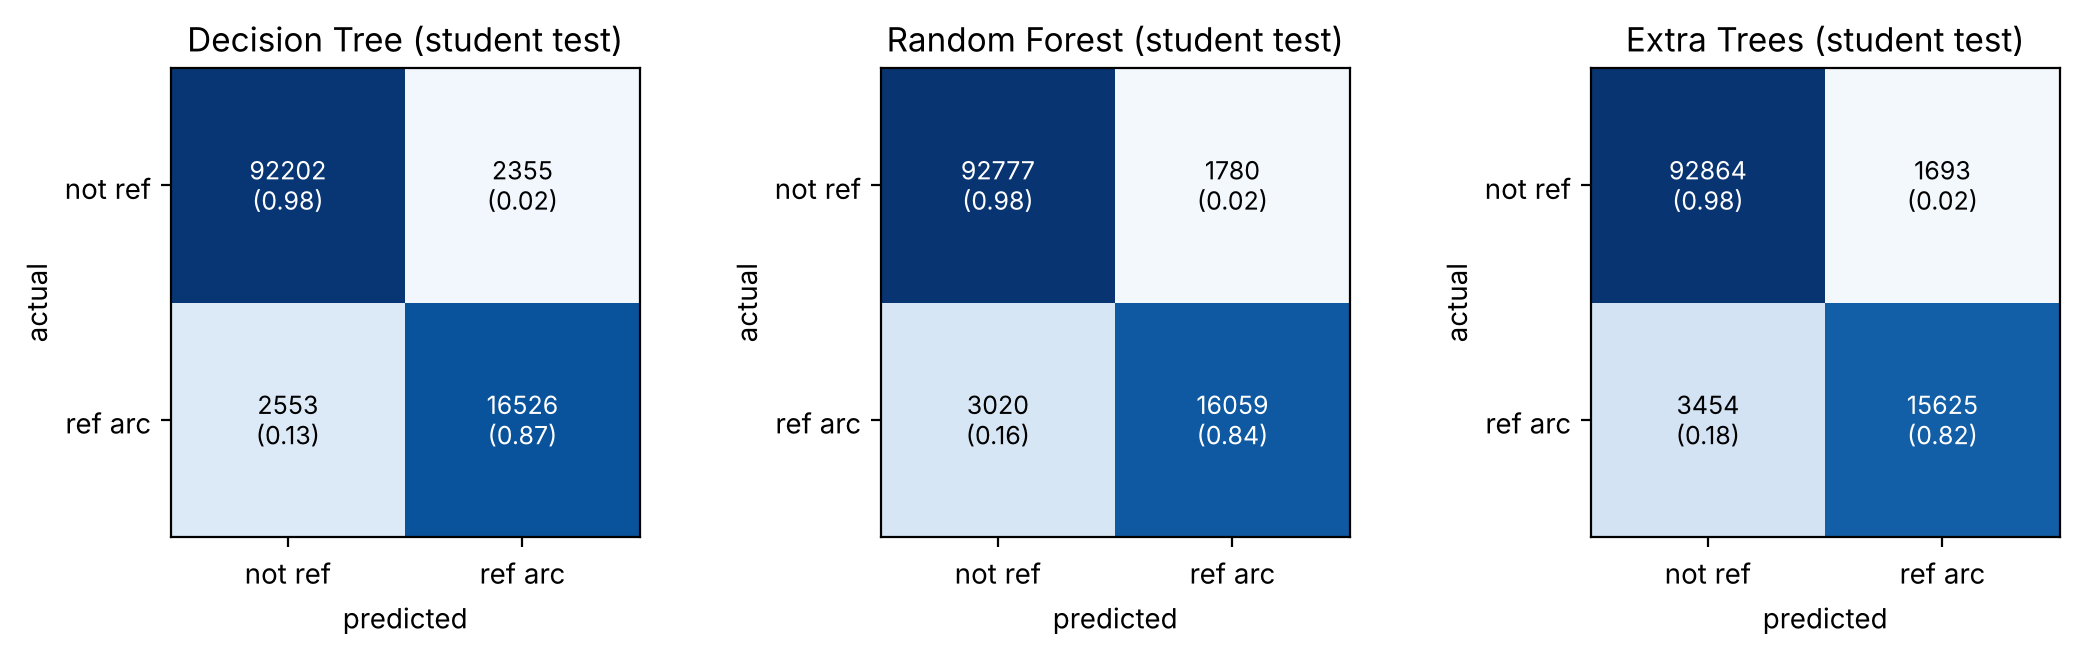

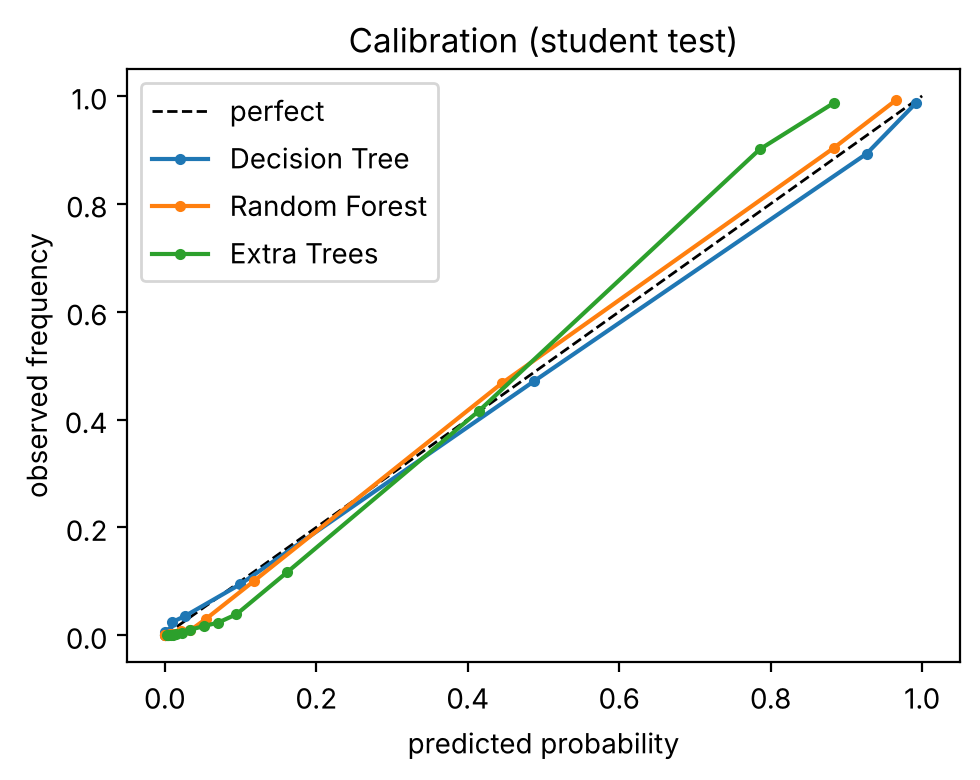

In [15]:
nb.plot_cv_folds({"Decision Tree": cv_dtree, "Random Forest": cv_rf, "Extra Trees": cv_extratrees})
nb.plot_overfit({"Decision Tree": (train_dtree, cv_dtree, test_dtree), "Random Forest": (train_rf, cv_rf, test_rf), "Extra Trees": (train_extratrees, cv_extratrees, test_extratrees)})
nb.plot_confusion({"Decision Tree": test_dtree["confusion"], "Random Forest": test_rf["confusion"], "Extra Trees": test_extratrees["confusion"]})
nb.plot_calibration(te.label.to_numpy(), {"Decision Tree": p_dtree, "Random Forest": p_rf, "Extra Trees": p_extratrees})

In [16]:
rows = []
for name, cv, t, h in [("Decision Tree", cv_dtree, test_dtree, hmm_dtree), ("Random Forest", cv_rf, test_rf, hmm_rf), ("Extra Trees", cv_extratrees, test_extratrees, hmm_extratrees)]:
    rows.append({"model": name, "CV macro F1": cv.macro_f1.mean(), "CV std": cv.macro_f1.std(),
                 "test Top-1": t["top1"], "test macro F1": t["macro_f1"], "test log loss": t["log_loss"],
                 "test continuity": t["continuity"], "Top-1 + HMM (trip mean)": h.hmm_top1.mean(),
                 "route F1 + HMM (trip mean)": h.hmm_route_f1.mean()})
pd.DataFrame(rows).set_index("model").round(4)

,CV macro F1,CV std,test Top-1,test macro F1,test log loss,test continuity,Top-1 + HMM (trip mean),route F1 + HMM (trip mean)
model,,,,,,,,
Decision Tree,0.9230,0.0160,0.8756,0.9224,0.1293,0.9231,0.9439,0.9539
Random Forest,0.9246,0.0163,0.8777,0.9224,0.1105,0.9253,0.9493,0.9577
Extra Trees,0.9176,0.0170,0.8552,0.9158,0.1400,0.9060,0.9478,0.9586
